# 💬 ChatGPT Sentiment Analysis — Çok Dilli Yorum Duygu Analizi

## 🎯 Problem
ChatGPT mobil uygulamasına farklı dillerde yazılmış kullanıcı yorumlarını İngilizceye çevirip temizleyerek **duygu analizini** (`positive` / `negative`) gerçekleştiriyoruz.

## 💡 Bu Notebook'tan Ne Öğreneceksin?
- Çok dilli metin verilerinde `langdetect` ile dil tespiti ve `deep_translator` ile otomatik İngilizce çeviri yapmayı
- Yıldız puanlarından (`rating`) ikili duygu etiketi (`sentiment`) türetmeyi
- NLP metin temizleme adımlarını (küçük harf, noktalama/rakam temizliği, stopword çıkarma, lemmatization) ve lemmatizer bug'ından kaçınmayı
- **TF-IDF veri sızıntısını (Data Leakage) önlemeyi:** önce `train_test_split`, ardından yalnızca eğitim verisine `fit_transform` uygulamayı
- `MultinomialNB` sınıflandırıcısı ile metin duygu sınıflandırması yapıp `classification_report` ve `confusion_matrix` ile değerlendirmeyi

## 📊 Veri Seti
- **Kaynak:** [Kaggle - ChatGPT App Reviews](https://www.kaggle.com/datasets/rubydoby/chatgpt-reviews)
- **Boyut:** `2.292` satır, `4` sütun (`date`, `title`, `review`, `rating`)
- **Hedef Değişken:** `sentiment` (`rating >= 3` → `positive`, `rating < 3` → `negative`)

## 1. Kütüphaneler ve Veri Yükleme

Veri işleme kütüphanelerini yükleyip `chatgpt_reviews.csv` veri setini okuyoruz.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/saloni1712/chatgpt-app-reviews/chatgpt_reviews.csv


In [2]:
df=pd.read_csv((__import__("glob").glob("/kaggle/input/**/chatgpt_reviews.csv", recursive=True)[0] if not os.path.exists("/kaggle/input/chatgpt-app-reviews/chatgpt_reviews.csv") else "/kaggle/input/chatgpt-app-reviews/chatgpt_reviews.csv"))
df.head()

,date,title,review,rating
0,2023-05-21 16:42:24,Much more accessible for blind users than the ...,Up to this point I’ve mostly been using ChatGP...,4
1,2023-07-11 12:24:19,"Much anticipated, wasn’t let down.",I’ve been a user since it’s initial roll out a...,4
2,2023-05-19 10:16:22,"Almost 5 stars, but… no search function",This app would almost be perfect if it wasn’t ...,4
3,2023-05-27 21:57:27,"4.5 stars, here’s why","I recently downloaded the app and overall, it'...",4
4,2023-06-09 07:49:36,"Good, but Siri support would take it to the ne...",I appreciate the devs implementing Siri suppor...,4


## 2. Veri İnceleme ve Tekrar Eden Yorumların Temizlenmesi

Sütun tiplerini, eksik değerleri (`isna().sum()`) ve tekrar eden (`duplicated`) yorumları kontrol ediyoruz. Aynı `review` metnine sahip kopya satırları veri setinden çıkarıyoruz.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2292 entries, 0 to 2291
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    2292 non-null   object
 1   title   2292 non-null   object
 2   review  2292 non-null   object
 3   rating  2292 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 71.8+ KB


In [4]:
df.isna().sum()

date      0
title     0
review    0
rating    0
dtype: int64

In [5]:
df[df.duplicated(subset=["review"])]

,date,title,review,rating
1351,2023-05-20 08:13:26,I need ipados version,Thanks,5
1508,2023-06-07 07:12:08,Please add sex or suggestive stuff bro please,Please,5
1783,2023-05-22 03:06:53,Best app ever,Love it,5
1800,2023-05-18 19:44:26,First,First,5
1801,2023-05-18 19:42:47,First,First,5
1802,2023-05-18 18:47:48,First,First,5
1827,2023-05-25 17:47:12,No iPad version?,Why?,1
1840,2023-05-18 19:58:30,First,First,4
1853,2023-05-18 22:32:50,Good,Very good,5
1866,2023-05-18 18:10:31,Ye,Pretty good,5


In [6]:
df=df.drop_duplicates(subset=["review"])

## 3. Duygu Etiketi (`sentiment`) Oluşturma ve Sınıf Dağılımı

Kullanıcı puanlarına (`rating`) göre ikili duygu etiketi oluşturuyoruz:
- `rating >= 3` → `positive`
- `rating < 3` → `negative`

Ardından sınıf dağılımını sayısal ve grafiksel olarak inceliyoruz.

In [7]:
a = df["rating"].value_counts()

def find_sent(a):
    if a>=3:
        return "positive"

    else:
        return "negative"

df["sentiment"]=df["rating"].apply(find_sent)

In [8]:
df.sample(5)

,date,title,review,rating,sentiment
1863,2023-05-19 11:01:26,WHAT A TIME TO BE ALIVE,Unbelievably amazing,5,positive
61,2023-05-26 23:43:59,Transcription and punctuation is nearly flawless!,"Okay, I'm using OpenAI's app itself to dictate...",4,positive
2023,2023-05-22 16:48:40,👍,"Отличное приложение, пока все устраивает",5,positive
954,2023-05-19 01:58:00,ChatGPT app,"""I'm very excited for this day, I've been wait...",5,positive
1159,2023-06-15 00:44:00,great app,Improve all kinds of efficiency in life.,5,positive


In [9]:
df["sentiment"].value_counts()

sentiment
positive    1626
negative     631
Name: count, dtype: int64

/tmp/ipykernel_16/788873026.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='sentiment', y='count', data=sent_val, palette='pastel')


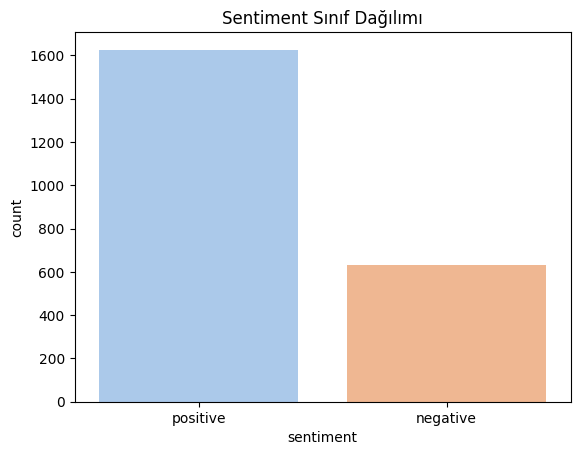

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sent_val=df["sentiment"].value_counts().reset_index()
sent_val.columns = ['sentiment', 'count']

sns.barplot(x='sentiment', y='count', data=sent_val, palette='pastel')
plt.title("Sentiment Sınıf Dağılımı")
plt.show()

## 4. Çok Dilli Yorumların Tespiti ve İngilizceye Çevrilmesi

Yorumlar arasında İngilizce dışında Çince, Korece, İspanyolca, Türkçe gibi birçok dil bulunmaktadır.
- `langdetect` ile yorumların dil dağılımını tespit ediyoruz.
- `deep_translator.GoogleTranslator` ile tüm yorumları İngilizceye çevirip `review_en` sütununa kaydediyoruz.

In [11]:
!pip install langdetect
from langdetect import detect

langs=[]

for text in df["review"]:
    try:
        langs.append(detect(text))

    except:
        langs.append("UnKnown")

pd.Series(langs).value_counts()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 8.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=04d86db24fae25c20c8c734819b43a4fdcebc66dd4f28e7b336394acef6775b4
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect


en         1905
zh-cn       129
ko           38
af           19
UnKnown      17
es           17
fr           12
ru           10
it           10
de            9
et            9
nl            9
so            8
id            8
ar            6
no            6
ca            6
vi            5
tl            4
sw            4
pl            4
zh-tw         4
cy            3
pt            3
ro            2
sl            2
fi            1
hr            1
sv            1
da            1
hu            1
bn            1
fa            1
tr            1
Name: count, dtype: int64

In [12]:
!pip install -q deep-translator
from deep_translator import GoogleTranslator
import time

_translator = GoogleTranslator(source="auto", target="en")
_reviews = df["review"].tolist()
_non_en_idx = [i for i, (t, l) in enumerate(zip(_reviews, langs)) if l != "en" and str(t).strip()]
_translated = list(_reviews)

for start in range(0, len(_non_en_idx), 25):
    batch_idx = _non_en_idx[start:start+25]
    batch_txt = [str(_reviews[i])[:4500] for i in batch_idx]
    try:
        res = _translator.translate_batch(batch_txt)
        for idx, tr in zip(batch_idx, res):
            if tr:
                _translated[idx] = tr
        time.sleep(0.5)
    except Exception:
        pass

df["review_en"] = _translated


In [13]:
df.sample(5)

,date,title,review,rating,sentiment,review_en
1436,2023-05-19 06:33:40,Cannot sign up,Cannot sign up. Doesn’t show keyboard when ent...,1,negative,Cannot sign up. Doesn’t show keyboard when ent...
1795,2023-05-19 22:16:21,yayyy update,first update!!,5,positive,first update!!
1894,2023-07-06 16:13:40,this request is invalid,this request is invalid,1,negative,this request is invalid
1746,2023-05-20 02:09:51,Exceptional AI Experience - ChatGPT Outshines ...,Rating: ★★★★★\n\nIn the ever-evolving landscap...,5,positive,Rating: ★★★★★\n\nIn the ever-evolving landscap...
2098,2023-05-19 13:47:37,No service in China,No,1,negative,No


## 5. Metin Ön İşleme (Text Cleaning) ve Bug Düzeltmeleri

### 🐛 Düzeltilen İki Kritik Bug

1. **Çevrilmiş Sütun (`review_en`) Kullanımı:**
   - ❌ Eski: `df["clean_review"] = df["review"].apply(clean_text)` — Çeviri yapıldığı halde orijinal çok dilli `review` sütunu temizleniyordu!
   - ✅ Yeni: `df["clean_review"] = df["review_en"].apply(clean_text)` — İngilizceye çevrilmiş `review_en` sütunu kullanılır.

2. **Lemmatizer Değişken Hatası:**
   - ❌ Eski: `tokens = [lemmatizer.lemmatize(text) for word in tokens]` — Her token için tek bir kelime (`word`) yerine tüm metin (`text`) lemmatize ediliyordu!
   - ✅ Yeni: `tokens = [lemmatizer.lemmatize(word) for word in tokens]` — Listedeki her `word` ayrı ayrı köküne indirgenir.

In [14]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = "" if pd.isna(text) else str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    text = " ".join(tokens)
    return text.strip()

df["clean_review"] = df["review_en"].apply(clean_text)

## 6. Kelime Bulutu (WordCloud) Görselleştirmesi

`positive` ve `negative` yorumlarda en sık geçen kelimeleri görselleştirerek veri hakkında sezgi kazanıyoruz.

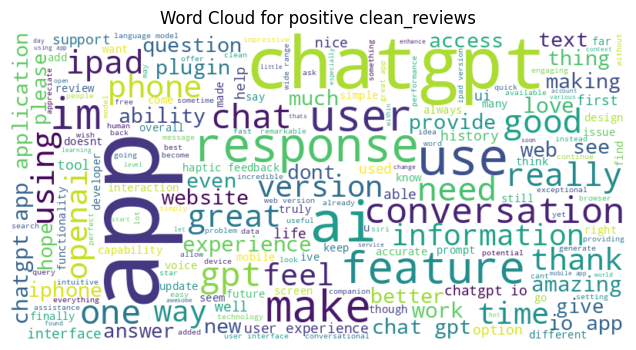

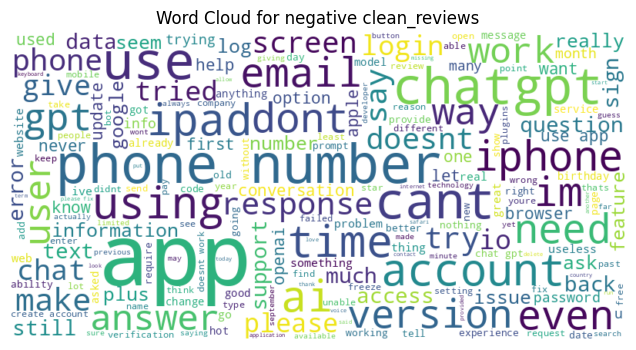

In [15]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

for sentiment in df["sentiment"].unique():
    text = " ".join(df[df["sentiment"] == sentiment]["clean_review"].astype(str))

    wordcloud=WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(text)

    plt.figure(figsize=(8,4))
    plt.axis("off")
    plt.imshow(wordcloud,interpolation="bilinear")
    plt.title(f"Word Cloud for {sentiment} clean_reviews")
    plt.show()

## 7. Train-Test Bölünmesi ve TF-IDF Vektörleştirme

### ⚠️ Kritik Düzeltme: TF-IDF Veri Sızıntısı (Data Leakage)

TF-IDF vektörleştirici, kelimelerin **IDF (Inverse Document Frequency)** ağırlıklarını ve kelime dağarcığını (vocabulary) veriden öğrenir.

```python
# ❌ YANLIŞ (Veri Sızıntısı): Tüm veri setine fit_transform uygulanıp sonra split yapılıyor
x = tfidf.fit_transform(df["clean_review"])
train_x, val_x, train_y, val_y = train_test_split(x, y, test_size=0.2, random_state=42)

# ✅ DOĞRU (Sızıntısız): Önce split yapılır, TF-IDF yalnızca eğitim verisine fit edilir
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train_vec = tfidf.fit_transform(x_train)   # Yalnızca train'den öğren
x_test_vec = tfidf.transform(x_test)         # Test'e sadece transform uygula
```

Test verisindeki kelime sıklıklarının eğitim aşamasına sızmasını önlemek için önce veriyi bölüyor, ardından `tfidf.fit_transform(x_train)` ve `tfidf.transform(x_test)` uyguluyoruz.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

x = df["clean_review"]
y = df["sentiment"]

# Önce eğitim ve test verilerini ayır (veri sızıntısını önlemek için)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# TF-IDF yalnızca eğitim verisine fit edilir, test verisine sadece transform uygulanır
tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
x_train_vec = tfidf.fit_transform(x_train)
x_test_vec = tfidf.transform(x_test)

In [17]:
#from tensorflow.keras.preprocessing.text import Tokenizer
#from tensorflow.keras.preprocessing.sequence import pad_sequences

#tokenizer=Tokenizer(num_words=1000,oov_token="<OOV>")
#tokenizer.fit_on_texts(df["clean_review"])

#sequences=tokenizer.texts_to_sequences(df["clean_review"])
#padded=pad_sequences(sequences,maxlen=100,padding="post")


# Deep learning kısmına geçince kullanırım küçük bir veri çok gerek yok

## 8. Model Eğitimi (`MultinomialNB`) ve Tahmin

Sınıf etiketlerini `LabelEncoder` ile sayısallaştırıyor (yalnızca `y_train` üzerine `fit_transform`, `y_test` üzerine `transform`), TF-IDF özellikleriyle `MultinomialNB` modelini eğitip test seti üzerinde tahmin üretiyoruz.

In [18]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import LabelEncoder

# Label Encoding
le = LabelEncoder()
train_y_enc = le.fit_transform(y_train)
test_y_enc = le.transform(y_test)

# Model oluştur ve fit et
mnb = MultinomialNB()
model = mnb.fit(x_train_vec, train_y_enc)

# Tahmin
pred = model.predict(x_test_vec)

# Tahminleri tekrar string etiketlere çevir
pred_labels = le.inverse_transform(pred)

## 9. Model Değerlendirmesi (`Accuracy`, `Classification Report`, `Confusion Matrix`)

Test setindeki tahminleri gerçek etiketlerle karşılaştırarak doğruluk (`accuracy_score`), makro F1 skoru (`f1_score`) ve karmaşıklık matrisini (`confusion_matrix`) inceliyoruz.

In [19]:
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, pred_labels))
print(classification_report(y_test, pred_labels, zero_division=0))
print("F1 score (macro):", f1_score(y_test, pred_labels, average='macro', zero_division=0))

Accuracy: 0.7942477876106194
              precision    recall  f1-score   support

    negative       0.79      0.38      0.52       130
    positive       0.79      0.96      0.87       322

    accuracy                           0.79       452
   macro avg       0.79      0.67      0.69       452
weighted avg       0.79      0.79      0.77       452

F1 score (macro): 0.6936665136310969


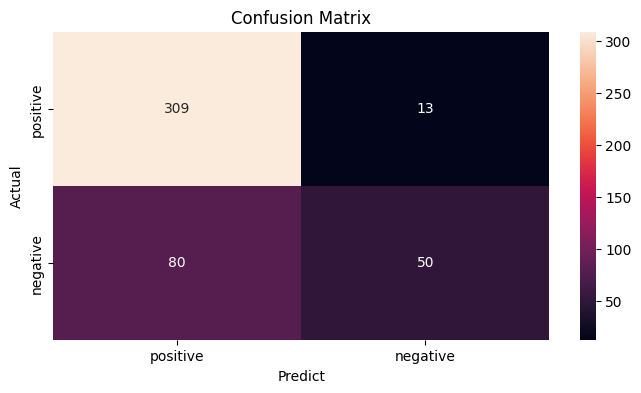

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred_labels, labels=["positive", "negative"])

plt.figure(figsize=(8, 4))
plt.title("Confusion Matrix")
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["positive", "negative"], yticklabels=["positive", "negative"])
plt.xlabel("Predict")
plt.ylabel("Actual")
plt.show()

## 📈 Özet: Düzeltilen Buglar ve Öğrenilenler

### 🐛 Düzeltilen Buglar
1. **TF-IDF Veri Sızıntısı (Data Leakage) Giderildi:**
   - ❌ Eski: `x = tfidf.fit_transform(df["clean_review"])` sonrasında `train_test_split` yapılıyordu.
   - ✅ Yeni: Önce `train_test_split`, ardından `tfidf.fit_transform(x_train)` ve `tfidf.transform(x_test)` uygulandı.
2. **Çevrilmiş Metin Sütunu (`review_en`) Kullanıldı:**
   - ❌ Eski: `df["clean_review"] = df["review"].apply(clean_text)`.
   - ✅ Yeni: `df["clean_review"] = df["review_en"].apply(clean_text)`.
3. **Lemmatizer Bug'ı Düzeltildi:**
   - ❌ Eski: `tokens = [lemmatizer.lemmatize(text) for word in tokens]`.
   - ✅ Yeni: `tokens = [lemmatizer.lemmatize(word) for word in tokens]`.

### 🔑 Öğrenilenler
- Metin vektörleştirme (`TfidfVectorizer`, `CountVectorizer`) her zaman `train_test_split` işleminden **sonra** ve yalnızca eğitim verisine `fit` edilerek uygulanmalıdır.
- Çok dilli veri setlerinde çeviri sonrası doğru sütunun (`review_en`) sonraki adımlara aktarıldığı mutlaka doğrulanmalıdır.
- Liste üreteçlerinde (list comprehension) döngü değişkeninin (`word`) doğru kullanılması, sessizce hatalı sonuç üreten mantık hatalarını önler.